# Task 1 – N-Queens: Propositional Logic (Glucose3) & Min-Conflicts
Run **Run All** on your own machine (macOS / Intel i5 is the evaluation config) so that every cell keeps its output before zipping. Cells marked *needs PySAT* require `pip install -r ../requirements.txt`.

In [1]:
import sys; sys.path.insert(0, '.')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from nqueens import *
from nqueens.benchmark import count_clauses, SATBenchmark, MinConflictsBenchmark
from nqueens.plots import plot_sat, plot_min_conflicts, plot_convergence
pd.set_option('display.width', 200)

## 1. Propositional formulation & CNF (Requirement 1)
Symbol `X(r,c)` = square (r,c) holds a queen; `var(r,c)=r*N+c+1`. Constraints: ≥1 queen per row, and `¬X(a) ∨ ¬X(b)` for each attacking pair found by `AttackConstraintDiscoverer`. See `docs/task1_theory.md`.

In [2]:
enc = NQueensCNFEncoder(4)
cnf = enc.encode()
print('variables:', cnf.num_vars, '| clauses:', cnf.num_clauses, '| closed form:', enc.theoretical_clause_count())
print(cnf.stats)
for c in cnf.clauses[:8]: print(c)

variables: 16 | clauses: 80 | closed form: 80
{'row_alo': 4, 'col_alo': 0, 'row_amo': 24, 'column_amo': 24, 'diag_main_amo': 14, 'diag_anti_amo': 14}
[1, 2, 3, 4]
[5, 6, 7, 8]
[9, 10, 11, 12]
[13, 14, 15, 16]
[-1, -2]
[-1, -3]
[-1, -4]
[-1, -5]


In [3]:
ns = [4, 6, 8, 10, 12, 16, 20, 24, 32, 40, 48, 64]
df_clauses = count_clauses(ns)
assert all(df_clauses['clauses'] == [NQueensCNFEncoder(n).theoretical_clause_count() for n in ns])
df_clauses

,N,variables,clauses,row_alo,col_alo,row_amo,column_amo,diag_main_amo,diag_anti_amo
0,4,16,80,4,0,24,24,14,14
1,6,36,296,6,0,90,90,55,55
2,8,64,736,8,0,224,224,140,140
3,10,100,1480,10,0,450,450,285,285
4,12,144,2608,12,0,792,792,506,506
5,16,256,6336,16,0,1920,1920,1240,1240
6,20,400,12560,20,0,3800,3800,2470,2470
7,24,576,21920,24,0,6624,6624,4324,4324
8,32,1024,52608,32,0,15872,15872,10416,10416
9,40,1600,103520,40,0,31200,31200,20540,20540


## 2. Glucose3 experiments (Requirement 2) – *needs PySAT*

In [4]:
res = GlucoseQueenSolver().solve(8)
print(res.board.render())
print('valid:', res.board.is_valid_solution(), '| clauses:', res.num_clauses, '| solve time: %.5fs' % res.solve_time)

. . Q . . . . .
. . . . . Q . .
. . . Q . . . .
. Q . . . . . .
. . . . . . . Q
. . . . Q . . .
. . . . . . Q .
Q . . . . . . .
valid: True | clauses: 736 | solve time: 0.00007s


In [5]:
sat_df = SATBenchmark(ns).run()
sat_df

N=   4 | clauses=       80 | solve=  0.0000s | total=   0.000s | valid=True
N=   6 | clauses=      296 | solve=  0.0001s | total=   0.000s | valid=True
N=   8 | clauses=      736 | solve=  0.0001s | total=   0.001s | valid=True
N=  10 | clauses=    1,480 | solve=  0.0002s | total=   0.002s | valid=True
N=  12 | clauses=    2,608 | solve=  0.0001s | total=   0.003s | valid=True
N=  16 | clauses=    6,336 | solve=  0.0015s | total=   0.012s | valid=True
N=  20 | clauses=   12,560 | solve=  0.0024s | total=   0.017s | valid=True
N=  24 | clauses=   21,920 | solve=  0.0018s | total=   0.069s | valid=True
N=  32 | clauses=   52,608 | solve=  0.0130s | total=   0.075s | valid=True
N=  40 | clauses=  103,520 | solve=  0.0763s | total=   0.243s | valid=True
N=  48 | clauses=  179,776 | solve=  0.6137s | total=   0.871s | valid=True
N=  64 | clauses=  428,800 | solve=  0.1617s | total=   0.847s | valid=True


,N,variables,clauses,sat,valid,encode_s,load_s,solve_s,total_s,conflicts,decisions
0,4,16,80,True,True,0.000085,0.000084,0.000033,0.000202,4,11
1,6,36,296,True,True,0.000257,0.000166,0.000065,0.000489,13,37
2,8,64,736,True,True,0.000431,0.000286,0.000055,0.000772,11,39
3,10,100,1480,True,True,0.000995,0.000562,0.000209,0.001766,41,101
4,12,144,2608,True,True,0.001620,0.001033,0.000120,0.002773,19,69
5,16,256,6336,True,True,0.007699,0.002655,0.001501,0.011855,181,406
6,20,400,12560,True,True,0.009865,0.004827,0.002375,0.017067,217,579
7,24,576,21920,True,True,0.055352,0.011568,0.001839,0.068758,178,619
8,32,1024,52608,True,True,0.041183,0.020358,0.012994,0.074535,648,1423
9,40,1600,103520,True,True,0.107516,0.059386,0.076285,0.243186,1916,3853


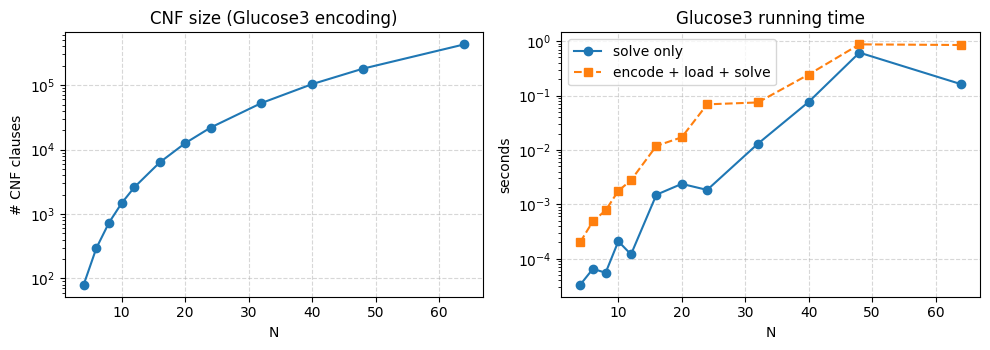

In [6]:
plot_sat(sat_df); plt.show()
sat_df.to_csv('results/sat_results.csv', index=False)

## 3. Min-Conflicts (Requirement 3)
Standard = random conflicted variable. Proposed = most-conflicted first + 5 % noise + 1-step tabu. Same seeds → same initial boards.

In [7]:
for sel in (RandomConflictedSelector(), MaxConflictSelector()):
    r = MinConflictsSolver(sel).solve(8, seed=1)
    print(sel.name, '| solved:', r.solved, '| steps:', r.steps, '| valid:', r.board.is_valid_solution())
print(r.board.render())

standard | solved: True | steps: 17 | valid: True
max_conflict | solved: True | steps: 8 | valid: True
. . Q . . . . .
. . . . . Q . .
. Q . . . . . .
. . . . Q . . .
. . . . . . . Q
Q . . . . . . .
. . . . . . Q .
. . . Q . . . .


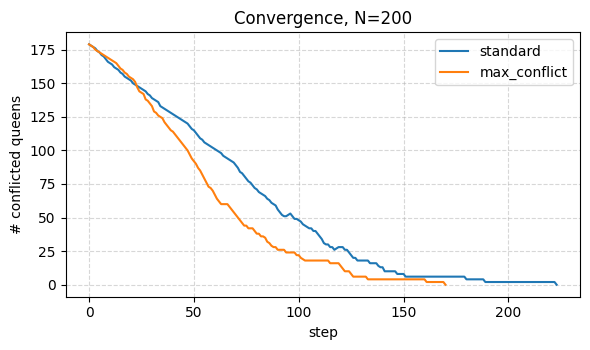

In [8]:
hist = {s.name: MinConflictsSolver(s).solve(200, seed=3, record_history=True).history
        for s in (RandomConflictedSelector(), MaxConflictSelector())}
plot_convergence(hist, 200); plt.show()

In [9]:
raw, summary = MinConflictsBenchmark([8, 16, 32, 64, 128, 256, 512, 1000, 2000], runs=30, max_steps=20000).run(verbose=False)
assert raw[raw.solved]['valid'].all()
summary.round(4)

,N,strategy,success_rate,mean_steps,median_steps,mean_time_s,std_time_s
0,8,max_conflict,1.0,17.8000,14.0,0.0010,0.0008
1,8,standard,1.0,56.8667,18.0,0.0027,0.0054
2,16,max_conflict,1.0,33.0667,27.5,0.0019,0.0010
3,16,standard,1.0,71.0333,61.0,0.0049,0.0046
4,32,max_conflict,1.0,46.7333,41.5,0.0026,0.0011
5,32,standard,1.0,81.0667,72.0,0.0043,0.0022
6,64,max_conflict,1.0,82.0333,77.0,0.0051,0.0018
7,64,standard,1.0,106.7667,107.0,0.0056,0.0025
8,128,max_conflict,1.0,112.1667,112.5,0.0083,0.0022
9,128,standard,1.0,152.6667,146.0,0.0084,0.0025


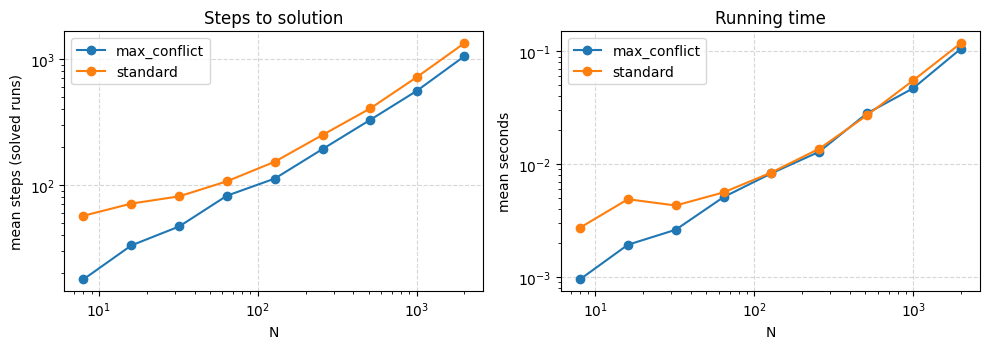

In [10]:
plot_min_conflicts(summary); plt.show()
raw.to_csv('results/mc_raw.csv', index=False); summary.to_csv('results/mc_summary.csv', index=False)

### Observations
* The heuristic needs ~20–45 % fewer repair steps for every N; time per step is slightly higher (extra tabu/max scan), so wall-clock gains are small for large N.
* Without restarts both variants can stall on tiny boards (N=8: 90–93 % success within 20 000 steps).